# Experiment: NLS-LSTM (non-local social pooling)

Messaoud et al., 2019. Extends CS-LSTM with a non-local social pooling: the target attends with multi-head attention over every occupied grid cell, alongside the local convolutional pooling; the decoder is conditioned on 3 lateral x 2 longitudinal manoeuvres. BAT Table 2: 0.56 / 1.22 / 2.02 / 3.03 / 4.30 m.

Part of the model comparison in `experiments/MODEL_ALTERNATIVES.md`. Run All; set `DEBUG = False` in section 2 for the real run.

## 0. Decisions & assumptions

Every choice that could change the result is listed here; the cell notes below repeat the ones that apply to each cell.

**Shared by every notebook (S)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| S1 | Same data for every model: NGSIM us-101 + i-80 (DEBUG: first 250k rows of us-101), scene-level 70/10/20 split, seed 42, train-only normalization. | Differences in the results must come from the model, not the data. | Papers use their own splits, so published numbers are not like-for-like with ours. |
| S2 | Same training budget for every model: config.py defaults (12 epochs, Adam lr 5e-4 decayed x0.6 per epoch, batch 128, weight decay 1e-5, grad clip 1.0). | A fair comparison; per-model tuning would favour whichever model got tuned most. | Each paper's own schedule (e.g. CS-LSTM trains longer with lr 1e-3). Tune later with --mode tune if a model looks under-trained. |
| S3 | Loss = MSE + bivariate-Gaussian NLL + neighbour-goal MSE (`basic_loss`); the risk-scaled loss is used only where this notebook's M table says so (STRAP-R-based variants). Models without a goal head output zero goals, so their goal term is a constant. A model may add its own `aux_loss` (only the diffusion model does). | Keeps one training objective; the risk-scaled loss is STRAP-R's own contribution. | Loss values are therefore not comparable across models: compare RMSE only. |
| S4 | Best checkpoint = lowest validation loss (`fit` default); test RMSE is reported at 1-5 s for that checkpoint. | Same selection rule for every model. | Selecting on val RMSE would be closer to the reported metric. |
| S5 | KNOWN LIMITATION (not fixed): positions are relative to the target at each timestep, so the target's own history is always (0, 0) and lateral speed is always 0 (NGSIM gives longitudinal speed only). The target is seen through speed, acceleration and lane features; lateral context comes from neighbours. | Kept as is (user decision) so every model gets identical inputs. | Papers feed the target's own x/y track; lane-change prediction is handicapped for all models here. |
| S6 | Neighbours = up to 15 risk-selected vehicles (S/O-field > RISK_THRESHOLD), not every nearby vehicle. | Same scene construction as STRAP. | Grid/graph papers use all vehicles in range; ours see only the risk-selected ones. |
| S7 | Output = one bivariate Gaussian per future step (mu_x, mu_y, sigma_x, sigma_y, rho); RMSE uses the mean. Multimodal models are moment-matched to one Gaussian. | The `fit` / `evaluate_trajectory` contract and how STRAP's Table I is scored. | minADE/minFDE over modes would favour multimodal models. |

**Specific to this model (M)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| M1 | Local branch = CS-LSTM's conv pooling; non-local branch = 4-head attention from the target encoding to every occupied cell (+ a learned cell-position embedding and a learned 'no neighbour' key). | The paper's local + non-local social pooling. | The null key avoids an all-masked attention when the grid is empty. |
| M2 | 6 manoeuvre modes (3 lateral x 2 longitudinal): a mode embedding is concatenated to the context; outputs moment-matched with p(lat) x p(lon). | Manoeuvre-based decoder as in the paper. | Paper outputs the most likely manoeuvre's trajectory. |
| M3 | Manoeuvre classes are supervised through `aux_loss` with labels from the true future: lane change if the 5 s lateral offset exceeds half a lane (1.85 m), braking if the mean future speed is below 0.8 x the current speed; cross-entropy weight 1. | The paper trains its manoeuvre head on labels; the `aux_loss` hook is the only place the true future reaches the model. | ASSUMPTION: papers label lane changes from lane IDs within +-4 s; ours uses the lateral offset at 5 s. |
| M4 | Sizes from `cs_lstm` (encoder 64, decoder 128). | Same backbone as CS-LSTM for a clean comparison. | - |

## 1. Setup

**Decisions in this cell:** seed fixed to `SEED` (42) in every notebook so initialisation is not a source of differences (S1).

In [1]:
import sys
from pathlib import Path

# Repo root = first folder upwards that contains src/ (works from experiments/ or the root).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import time
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from src.config import (
    BATCH_SIZE, BETA_LOSS, DEBUG_MAX_ROWS, DEVICE, DROPOUT, DT, LEARNING_RATE, LR_DECAY, N_V,
    NGSIM_LOCATIONS, NUM_EPOCHS, NORMALIZATION_FILE, SEED, STATE_DIM, TF_STEPS, TH_STEPS, WEIGHT_DECAY,
)
from src.data.loader import NGSIMDataLoader, create_dataloader
from src.data.normalization import load_stats, normalize_samples
from src.evaluation.evaluate import evaluate_trajectory
from src.models.strap import STRAP
from src.pipeline import collision_scores, metric_rows, test_groups
from src.train import fit, prepare_data
from experiments.benchmark import compare, save_result

torch.manual_seed(SEED)
print("device:", DEVICE)

/home/st_students/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


device: cuda


## 2. Experiment config

**Decisions in this cell:** training budget is config.py's (S2); `use_risk_loss` as in the M table; collisions scored at 2 m like `--mode collisions`.

In [2]:
EXP_NAME = "nls_lstm"          # unique per notebook -> experiments/results/<EXP_NAME>.json
DESCRIPTION = "NLS-LSTM: conv social pooling + non-local multi-head attention, manoeuvre-supervised"

DEBUG = False                  # True: DEBUG_MAX_ROWS of us-101 for a quick check; False: full data
LOCATIONS = ["us-101"] if DEBUG else NGSIM_LOCATIONS

HPARAMS = dict(               # keyword args of src.train.fit
    num_epochs=NUM_EPOCHS,
    use_risk_loss=False,       # False = basic loss (STRAP-B style)
    beta=BETA_LOSS,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    lr_decay=LR_DECAY,
    weight_decay=WEIGHT_DECAY,
)

RUN_COLLISIONS = False         # per-pair collision scoring on the test split (slow on full data)
COLLISION_THRESHOLD = 2.0     # metres, GT collision label distance

CKPT_DIR = ROOT / "experiments" / "checkpoints" / EXP_NAME

## 3. Data
Train-only normalization stats and the intention codebook are written to `CKPT_DIR`.

**Decisions in this cell:** same loader, split and train-only normalization as every other notebook (S1, S6); `norm_stats` is loaded here so the model (next section) can recover metres and lane numbers.

In [3]:
loader = NGSIMDataLoader(locations=LOCATIONS, max_rows=DEBUG_MAX_ROWS if DEBUG else None)
train_s, val_s, centers = prepare_data(loader, save_dir=str(CKPT_DIR))
_, _, test_raw = loader.get_splits()   # cached; raw (unnormalized) test split
# Train-only mean/std; models that need metres or lane numbers undo the normalization with it.
norm_stats = load_stats(str(CKPT_DIR / NORMALIZATION_FILE))
print(f"train/val/test = {len(train_s)}/{len(val_s)}/{len(test_raw)}")

2026-10-30 00:16:50,509 - STRAP - INFO - [NGSIMLoader] Loading cached data from /home/st_students/MTP/data/raw/ngsim/ngsim_us-101.csv


2026-10-30 00:16:57,901 - STRAP - INFO - [NGSIMLoader] Dropping 704,000 duplicate rows (0 duplicate groups differ in other columns)


2026-10-30 00:16:58,712 - STRAP - INFO - [NGSIMLoader] 'us-101' period 1: 1,180,598 rows, frame_id offset=0


2026-10-30 00:16:58,737 - STRAP - INFO - [NGSIMLoader] 'us-101' period 2: 1,403,095 rows, frame_id offset=9609


2026-10-30 00:16:58,764 - STRAP - INFO - [NGSIMLoader] 'us-101' period 3: 1,515,240 rows, frame_id offset=19680


...

2026-10-30 00:36:58,669 - STRAP - INFO - [Train] Fitting k-means intention codebook on training data...


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


2026-10-30 00:37:28,148 - STRAP - INFO - [Train] Saved intention codebook ((100, 4)) to /home/st_students/MTP/experiments/checkpoints/nls_lstm/intention_clusters.pkl


2026-10-30 00:37:29,677 - STRAP - INFO - [NGSIMLoader] Per-recording temporal split over 6 recordings: train=540149 {'i-80': 287507, 'us-101': 252642}, val=86077 {'i-80': 50059, 'us-101': 36018}, test=121130 {'i-80': 58995, 'us-101': 62135}


train/val/test = 540149/86077/121130


## 4. Model

Any `torch.nn.Module` works if `forward(states, mask, dims)` returns a 3-tuple:

| output | shape | meaning |
|---|---|---|
| `traj_dist` | `(B, T_f=50, 5)` | `[mu_x, mu_y, sigma_x, sigma_y, rho]` of the target, metres relative to its last observed position (x longitudinal, y lateral); `sigma > 0`, `rho` in (-1, 1) |
| `goals` | `(B, N-1, 4)` | neighbour goals; a model without a goal head returns `states.new_zeros(B, N - 1, 4)` |
| third | anything | ignored by training/eval (STRAP returns its risk field) |

Inputs: `states (B, T_h=30, N, 11)` normalized (vehicle 0 = target, rest neighbours, zero-padded),
`mask (B, N)` True = real vehicle, `dims (B, N, 2)` raw length/width in metres.
Feature index: 0 rel-longitudinal m, 1 rel-lateral m, 2 speed/30, 3 lateral speed (always 0), 4 accel/10,
5 type/2, 6 relative lane (target - vehicle, left = +), 7 length/10, 8 width/3, 9 S-field risk, 10 O-field risk.
Raw value = `states * std + mean` with `norm_stats`. STRAP's k-means codebook is only loaded if the model has a `risk_decoder`.

**Decisions in this cell:** local conv + non-local attention pooling (M1), manoeuvre-conditioned decoder (M2) with label supervision via `aux_loss` (M3). Built after the data cell because it needs `norm_stats`.

In [4]:
def moment_match(raw, weights):
    """(B, M, T, 5) raw mode outputs + (B, M) mode weights -> (B, T, 5) one Gaussian (S7)."""
    mu = raw[..., :2]
    sig = F.softplus(raw[..., 2:4]) + 1e-3
    rho = torch.tanh(raw[..., 4])
    w = weights[:, :, None]                                         # (B, M, 1)
    mean = (w[..., None] * mu).sum(1)                               # (B, T, 2)
    d = mu - mean[:, None]
    var = (w[..., None] * (sig ** 2 + d ** 2)).sum(1)
    cov = (w * (rho * sig[..., 0] * sig[..., 1] + d[..., 0] * d[..., 1])).sum(1)
    sx, sy = var[..., 0].sqrt(), var[..., 1].sqrt()
    return torch.stack([mean[..., 0], mean[..., 1], sx, sy, (cov / (sx * sy)).clamp(-0.999, 0.999)], dim=-1)

class VehicleEncoder(nn.Module):
    """Shared per-vehicle encoder: FC + leaky ReLU + LSTM over the 30 history steps."""
    def __init__(self, input_dim=STATE_DIM, emb=32, d=64):
        super().__init__()
        self.embed = nn.Linear(input_dim, emb)
        self.lstm = nn.LSTM(emb, d, batch_first=True)

    def forward(self, x):                                           # x (B, T, N, F)
        B, T, N, D_in = x.shape
        seq, (h, _) = self.lstm(F.leaky_relu(self.embed(x.transpose(1, 2).reshape(B * N, T, D_in)), 0.1))
        return seq.reshape(B, N, T, -1), h[-1].reshape(B, N, -1)   # per-step and last-step encodings

def social_grid(raw_last, mask, h, rows=13, cols=3, cell=4.572):
    """Scatter neighbour vectors h (B, N, C) into a (B, C, rows, cols) grid by longitudinal offset
    (feature 0) and relative lane (feature 6, left = +) at the last step; the target is left out."""
    B, N, C = h.shape
    row = torch.floor(raw_last[..., 0] / cell + rows / 2).long()
    col = (cols // 2 - torch.round(raw_last[..., 6])).long()
    inside = mask & (row >= 0) & (row < rows) & (col >= 0) & (col < cols)
    inside[:, 0] = False
    b, v = inside.nonzero(as_tuple=True)
    grid = h.new_zeros(B, rows * cols, C)
    grid[b, row[b, v] * cols + col[b, v]] = h[b, v]                 # two vehicles in one cell: the later one wins
    return grid.view(B, rows, cols, C).permute(0, 3, 1, 2)

def decode_modes(decoder, head, ctx, weights, T_f=TF_STEPS):
    """ctx (B, M, C): one context per mode, fed at every step of a shared LSTM decoder;
    the M raw outputs are moment-matched with `weights` (B, M) into one Gaussian (S7)."""
    B, M, _ = ctx.shape
    h, _ = decoder(ctx.reshape(B * M, 1, -1).expand(-1, T_f, -1))
    return moment_match(head(h).reshape(B, M, T_f, 5), weights)

LANE_HALF = 1.85   # m, half of a 3.7 m lane (assumption)


def manoeuvre_labels(gt, speed0, horizon=TF_STEPS * DT):
    """Labels from the true future: lateral 0 keep / 1 left / 2 right from the 5 s lateral offset
    (+y = right); longitudinal 0 normal / 1 brake if the mean future speed < 0.8 x current speed."""
    y = gt[:, -1, 1]
    lat = torch.where(y < -LANE_HALF, 1, torch.where(y > LANE_HALF, 2, 0))
    lon = (gt[:, -1, 0] / horizon < 0.8 * speed0).long()
    return lat, lon


def manoeuvre_weights(lat_logits, lon_logits):
    """p(lat) x p(lon) -> (B, n_lat * n_lon), mode index = lat * n_lon + lon."""
    return (F.softmax(lat_logits, -1)[:, :, None] * F.softmax(lon_logits, -1)[:, None]).flatten(1)

class NLSLSTM(nn.Module):
    def __init__(self, norm_stats, d=64, dyn=32, dec=128, heads=4):
        super().__init__()
        self.register_buffer("mean", torch.tensor(norm_stats["mean"]))
        self.register_buffer("std", torch.tensor(norm_stats["std"]))
        self.encoder = VehicleEncoder(STATE_DIM, 32, d)
        self.dyn = nn.Linear(d, dyn)
        self.conv1, self.conv2 = nn.Conv2d(d, 64, 3), nn.Conv2d(64, 16, (3, 1))
        self.pool = nn.MaxPool2d((2, 1), padding=(1, 0))
        self.cell_pos = nn.Parameter(torch.zeros(39, d))
        self.null = nn.Parameter(torch.zeros(1, 1, d))
        self.non_local = nn.MultiheadAttention(d, heads, batch_first=True)
        ctx = dyn + 80 + d
        self.op_lat, self.op_lon = nn.Linear(ctx, 3), nn.Linear(ctx, 2)
        self.mode_embed = nn.Embedding(6, 16)
        self.decoder = nn.LSTM(ctx + 16, dec, batch_first=True)
        self.head = nn.Linear(dec, 5)

    def encode(self, states, mask):
        B = states.shape[0]
        _, h = self.encoder(states)
        grid = social_grid(states[:, -1] * self.std + self.mean, mask, h)
        local = self.pool(F.leaky_relu(self.conv2(F.leaky_relu(self.conv1(grid), 0.1)), 0.1)).flatten(1)
        cells = grid.flatten(2).transpose(1, 2)                     # (B, 39, d)
        keys = torch.cat([self.null.expand(B, -1, -1), cells + self.cell_pos], dim=1)
        pad = torch.cat([torch.zeros(B, 1, dtype=torch.bool, device=states.device), cells.abs().sum(-1) == 0], dim=1)
        nl, _ = self.non_local(h[:, :1], keys, keys, key_padding_mask=pad)
        ctx = torch.cat([F.leaky_relu(self.dyn(h[:, 0]), 0.1), local, nl[:, 0]], dim=-1)
        return ctx, self.op_lat(ctx), self.op_lon(ctx)

    def forward(self, states, mask, dims=None):
        B, _, N, _ = states.shape
        ctx, lat, lon = self.encode(states, mask)
        mode_ctx = torch.cat([ctx[:, None].expand(-1, 6, -1), self.mode_embed.weight[None].expand(B, -1, -1)], -1)
        return decode_modes(self.decoder, self.head, mode_ctx, manoeuvre_weights(lat, lon)), states.new_zeros(B, N - 1, 4), None

    def aux_loss(self, states, mask, dims, gt):                     # M3
        _, lat, lon = self.encode(states, mask)
        lat_y, lon_y = manoeuvre_labels(gt, (states[:, -1, 0, 2] * self.std[2] + self.mean[2]) * 30.0)
        return F.cross_entropy(lat, lat_y) + F.cross_entropy(lon, lon_y)


def build_model():
    return NLSLSTM(norm_stats)

model = build_model().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"{type(model).__name__}: {n_params:,} parameters")

NLSLSTM: 253,258 parameters


## 5. Train

**Decisions in this cell:** `fit` with the config budget (S2); best checkpoint by val loss (S4). Loss curves are only comparable within this notebook (S3).

2026-10-30 00:37:30,524 - STRAP - INFO - Training STRAP on cuda


2026-10-30 00:37:30,525 - STRAP - INFO - Epochs: 12, Risk Loss: False, Beta: 0.0, LR: 0.0005, Batch: 128, LR decay: 0.6, Weight decay: 1e-05


2026-10-30 00:37:30,526 - STRAP - INFO - Number of training batches: 4220


2026-10-30 00:37:30,527 - STRAP - INFO - Number of validation batches: 673


2026-10-30 00:39:13,329 - STRAP - INFO - Epoch 1/12: Train Loss=657.2572 (goal=598.7875, traj=58.0305), Val Loss=392.8028, Val RMSE=2.3790


...

2026-10-30 01:02:36,362 - STRAP - INFO - Epoch 10/12: Train Loss=606.0437 (goal=598.7885, traj=6.9127), Val Loss=391.8002, Val RMSE=2.2048


2026-10-30 01:04:24,981 - STRAP - INFO - Epoch 11/12: Train Loss=606.0358 (goal=598.7871, traj=6.9063), Val Loss=391.7993, Val RMSE=2.2050


2026-10-30 01:06:15,873 - STRAP - INFO - Epoch 12/12: Train Loss=606.0291 (goal=598.7854, traj=6.9014), Val Loss=391.7761, Val RMSE=2.2005


2026-10-30 01:06:15,895 - STRAP - INFO - Training complete!


,epoch,train_loss,goal_loss,traj_loss,val_loss,val_rmse,lr
0,1,657.257239,598.787495,58.030498,392.802771,2.378964,0.000300
1,2,607.256106,598.785566,8.106968,392.814458,2.384163,0.000180
2,3,606.595498,598.785684,7.456837,392.059416,2.246524,0.000108
3,4,606.368869,598.789060,7.231453,391.862950,2.208663,0.000065
4,5,606.238834,598.790953,7.101989,391.857719,2.209894,0.000039
5,6,606.161071,598.787937,7.028977,391.776098,2.197692,0.000023
6,7,606.109445,598.788297,6.977833,391.746603,2.193261,0.000014
7,8,606.073433,598.787167,6.943311,391.799978,2.201994,0.000008
8,9,606.054497,598.786889,6.924983,391.761818,2.197099,0.000005
9,10,606.043659,598.788549,6.912662,391.800183,2.204794,0.000003


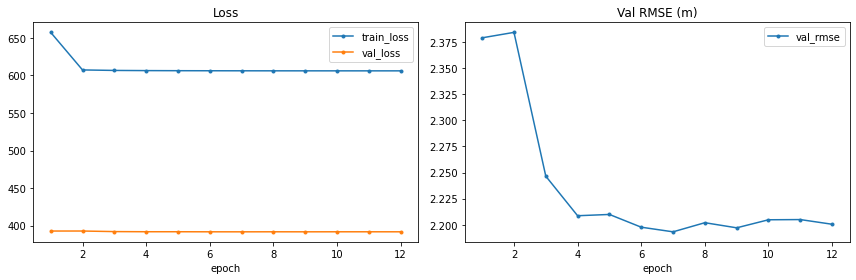

In [5]:
t0 = time.time()
training_log = fit(model, train_s, val_s, centers, save_dir=str(CKPT_DIR), **HPARAMS)
train_minutes = (time.time() - t0) / 60

log_df = pd.DataFrame(training_log)
display(log_df)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
log_df.plot(x="epoch", y=["train_loss", "val_loss"], marker=".", ax=axes[0], title="Loss")
log_df.plot(x="epoch", y="val_rmse", marker=".", ax=axes[1], title="Val RMSE (m)")
plt.tight_layout(); plt.show()

## 6. Evaluate (best checkpoint) — RMSE 1s…5s overall, per site, zero-neighbour scenes

**Decisions in this cell:** RMSE of the predicted mean at 1-5 s on the test split, overall / per site / target-only scenes (S7).

In [6]:
model.load_state_dict(torch.load(CKPT_DIR / "best_model.pt", map_location=DEVICE, weights_only=True))
model.eval()
test_s = normalize_samples(test_raw, norm_stats)

test_metrics = {}
for label, samples in test_groups(test_s).items():
    dl = create_dataloader(samples, batch_size=32, shuffle=False)
    test_metrics[label] = {**evaluate_trajectory(model, dl, DEVICE), "n": len(samples)}
display(pd.DataFrame(test_metrics).T)

,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,n
NGSIM Test Split,0.478187,1.168229,2.028988,3.129995,4.498926,2.260865,121130.0
site us-101,0.446424,1.124078,2.002659,3.167677,4.650486,2.278265,62135.0
zero-neighbour samples,0.573418,1.363851,2.361421,3.601939,5.094158,2.598957,3120.0
site i-80,0.509509,1.212997,2.056270,3.089691,4.333439,2.240381,58995.0


## 7. Collision prediction (optional)
Model's predicted target vs constant-velocity neighbours, every risk metric at its default threshold.

**Decisions in this cell:** neighbours are rolled forward at constant velocity and candidates are the nearest vehicles at the last history step, as in `--mode collisions`; only the target trajectory comes from this model.

In [7]:
collisions = None
if RUN_COLLISIONS:
    scores, gt, _ = collision_scores(model, loader, test_raw, norm_stats, COLLISION_THRESHOLD)
    collisions = {"threshold": COLLISION_THRESHOLD, "n_pairs": len(gt),
                  "n_gt_collisions": int(gt.sum()), "rows": metric_rows(scores, gt)}
    print(f"{len(gt)} pairs, {int(gt.sum())} GT collisions")
    display(pd.DataFrame(collisions["rows"]).set_index("metric"))

## 8. Save result

**Decisions in this cell:** one JSON per `EXP_NAME`; a rerun overwrites it.

In [8]:
save_result({
    "name": EXP_NAME,
    "description": DESCRIPTION,
    "model_class": type(model).__name__,
    "n_params": n_params,
    "hparams": HPARAMS,
    "data": {"locations": LOCATIONS, "debug": DEBUG},
    "train_minutes": train_minutes,
    "training_log": training_log,
    "test": test_metrics,
    "collisions": collisions,
})

Saved /home/st_students/MTP/experiments/results/nls_lstm.json


PosixPath('/home/st_students/MTP/experiments/results/nls_lstm.json')

## 9. Comparison & benchmarking — all results in `experiments/results/`

Ranked by overall test `rmse_avg` (best per column highlighted). Check the `data` column:
debug and full-data runs are listed together but are not comparable.
Also written to `experiments/comparison_rmse.csv` / `comparison_collisions.csv`.

**Decisions in this cell:** compares every saved result; only rows with the same `data` value are like-for-like.

,description,data,epochs,n_params,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,site us-101 avg,zero-neighbour samples avg,site i-80 avg
model,,,,,,,,,,,,,
miat,MIAT: temporal transformer + spatial attention + weighted manoeuvre-intention supervision,"us-101,i-80",12,194986,0.4489,1.1007,1.8873,2.8658,4.0551,2.0716,2.0952,2.4868,2.0456
dacr_amtp,"LOOSE: per-step dynamic attention + GRU context reasoning, 6 multimodal queries","us-101,i-80",12,254150,0.4603,1.1221,1.9212,2.9094,4.1144,2.1055,2.0954,2.4974,2.1150
mfp,"MFP: GRU encoders + attention, 5 latent modes, autoregressive GRU decoders","us-101,i-80",12,77786,0.4536,1.1207,1.9280,2.9284,4.1388,2.1139,2.1002,2.5112,2.1274
cognitive,"Cognitive-driven: safety (TTC/TET/TIT) + behaviour centrality + priority attention, Leanformer fusion","us-101,i-80",12,227979,0.4624,1.1204,1.9247,2.9255,4.1366,2.1139,2.0999,2.5102,2.1276
inatran,LOOSE: interaction-aware spatio-temporal transformer with future-step queries,"us-101,i-80",12,173381,0.4740,1.1277,1.9305,2.9271,4.1289,2.1176,2.1055,2.5476,2.1297
mha_lstm,MHA-LSTM: each attention head over neighbours yields one trajectory mode,"us-101,i-80",12,146825,0.4637,1.1367,1.9448,2.9449,4.1597,2.1300,2.1281,2.5236,2.1308
gava,LOOSE (name only): gated attention + conditional VAE,"us-101,i-80",12,210757,0.4679,1.1431,1.9574,2.9665,4.1877,2.1445,2.1282,2.5460,2.1605
fhif,LOOSE: individual / pairwise / group interaction features fused hierarchically with gates,"us-101,i-80",12,171141,0.4782,1.1477,1.9584,2.9617,4.1814,2.1455,2.1451,2.5409,2.1447
hltp,"HLTP teacher: adaptive visual-sector pooling + LSTM/attention + GAT + iTransformer fusion, manoeuvre-supervised","us-101,i-80",12,232050,0.4920,1.1527,1.9621,2.9713,4.2036,2.1564,2.1293,2.5414,2.1834


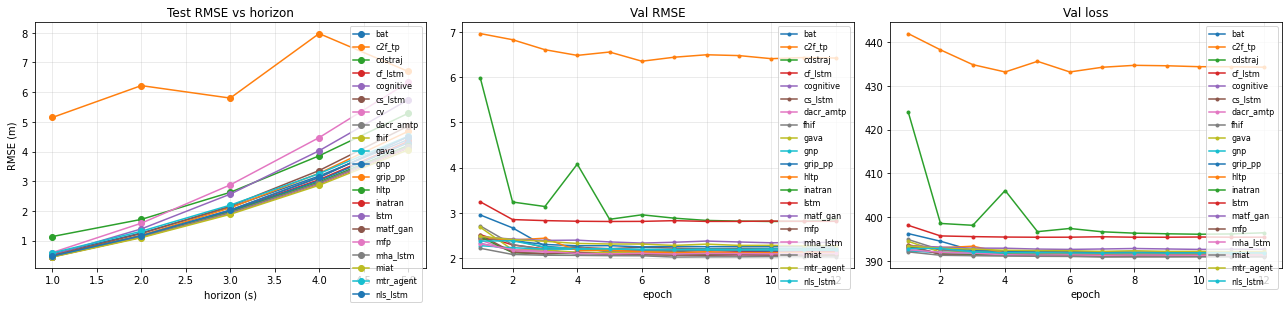

In [9]:
rmse_df, collision_df = compare()